# 00c · EverydayScents: segmentation

**Purpose.** Cut each sample out of its session CSV by phase and time window, pivot long to wide, use `voltage_v`, resample baseline to 60 points and sampling to 150 points (T = 210), and subtract the baseline mean per sensor. The cleaning phase is not used.

**Inputs**
- `data/raw/everyday_scents/session_<id>.csv`: long format (timestamp, phase, sensor, value, raw, voltage_v, gain)
- `data/processed/everyday_scents/meta.csv`: 155 rows (from 00b)

**Outputs**
- `data/processed/everyday_scents/X_signals.npy`: (144, 11, 210), channels hcho, ch4, voc, odor, etoh, h2s, no2, nh3, co, smoke, h2

**Note.** 11 of the 155 labelled samples are aborted or restarted recordings (sampling phase of 0 to 15 s) and are dropped here: 144 samples remain (33 ambient / 39 coffee / 50 truffle / 22 black_pepper), and `meta.csv` is rewritten with those 144 rows.

In [1]:
import sys
sys.path.append("../..")          # project root, so that `import src` works

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")
from src import load_es
from src.preprocess import baseline_correct, resample

RAW = ROOT / "data/raw/everyday_scents"
OUT = ROOT / "data/processed/everyday_scents"
T_BASE, T_SAMP = 60, 150     # points for the baseline and the sampling phase
MIN_POINTS = 20              # a phase with fewer raw points is flagged

meta = pd.read_csv(OUT / "meta.csv", parse_dates=["base_start", "base_end", "samp_start", "samp_end"])
len(meta)

155

## Cut every sample out of its session, resample each phase, join them

In [2]:
X = np.empty((len(meta), len(load_es.CHANNELS), T_BASE + T_SAMP), dtype=np.float32)   # (155, 11, 210)
info_rows = []
for sid, idx in meta.groupby("session_id").groups.items():
    session = load_es.read_session_csv(RAW, sid)
    for i in idx:
        (tb, xb), (ts, xs) = load_es.segment(session, meta.loc[i])     # (11, Tb_raw), (11, Ts_raw)
        info_rows.append({"i": i, "n_base_raw": len(tb), "n_samp_raw": len(ts),
                          "base_sec": tb[-1] - tb[0] if len(tb) else 0,
                          "samp_sec": ts[-1] - ts[0] if len(ts) else 0})
        if len(tb) < MIN_POINTS or len(ts) < MIN_POINTS:
            X[i] = np.nan
            continue
        X[i, :, :T_BASE] = resample(xb, tb, T_BASE)                     # (11, 60)
        X[i, :, T_BASE:] = resample(xs, ts, T_SAMP)                     # (11, 150)
seg = pd.DataFrame(info_rows).set_index("i").sort_index()
meta = meta.join(seg)
seg.describe()

,n_base_raw,n_samp_raw,base_sec,samp_sec
count,155.00000,155.000000,155.000000,155.000000
mean,133.03871,205.174194,198.338065,307.520645
std,42.13705,77.052196,63.133050,115.938159
min,3.00000,0.000000,3.100000,0.000000
25%,118.00000,197.000000,177.200000,297.600000
50%,120.00000,199.000000,178.500000,298.000000
75%,156.00000,205.000000,236.800000,299.150000
max,202.00000,402.000000,298.900000,599.300000


## Incomplete recordings
Some labelled samples were aborted or restarted: their sampling phase lasts only a few seconds
(or the session file ends before it starts), so they have almost no points to build a sample from.
Rule: a sample is kept only if both phases have at least `MIN_POINTS` raw readings per channel.

In [3]:
good = np.isfinite(X).all(axis=(1, 2))                    # (155,)
bad = meta[~good]
print(len(bad), "samples dropped as incomplete recordings")
bad[["session_id", "sample_id", "class", "n_base_raw", "n_samp_raw", "base_sec", "samp_sec"]]

11 samples dropped as incomplete recordings


,session_id,sample_id,class,n_base_raw,n_samp_raw,base_sec,samp_sec
0,session_20260703_133943,truffle_001,truffle,39,3,58.0,3.1
1,session_20260707_101250,coffee_001_ground_rep_001,coffee,40,0,58.1,0.0
21,session_20260708_152343,fresh_truffle_002_rep1,truffle,3,6,3.1,6.3
22,session_20260708_153934,fresh_truffle_002_rep1,truffle,52,0,75.3,0.0
28,session_20260714_124233,coffee_001_ground_rep_003,coffee,198,0,297.9,0.0
30,session_20260714_140648,truffle_001_rep2,truffle,192,0,283.8,0.0
46,session_20260723_123126,coffee_001,coffee,195,0,297.6,0.0
128,session_20260731_151247,ambient_rep_001,ambient,5,0,6.3,0.0
130,session_20260731_151343,ambient_rep_002,ambient,117,1,177.3,0.0
142,session_20260805_081712,ambient_001_rep001,ambient,6,6,7.8,7.8


In [4]:
X = X[good]                                                 # (144, 11, 210)
meta = meta[good].reset_index(drop=True)
print(meta["class"].value_counts().reindex(load_es.CLASSES))

baseline_level = X[:, :, :T_BASE].mean(axis=2)              # (N, 11) resting level, kept for R2 and C5
X = baseline_correct(X, T_BASE).astype(np.float32)          # (N, 11, 210)
assert X.shape == (len(meta), 11, 210) and np.isfinite(X).all()
print(X.shape)

class
ambient         33
coffee          39
truffle         50
black_pepper    22
Name: count, dtype: int64
(144, 11, 210)


## One sample after segmentation

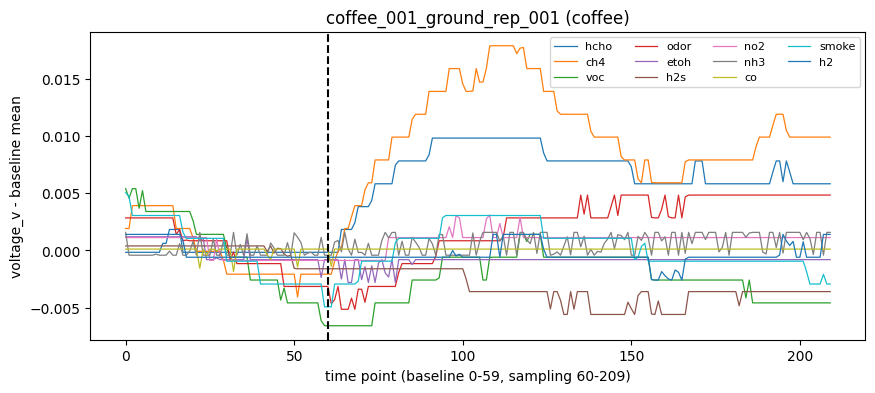

In [5]:
i = meta.index[meta["class"] == "coffee"][0]
fig, ax = plt.subplots(figsize=(10, 4))
for c, name in enumerate(load_es.CHANNELS):
    ax.plot(X[i, c], lw=0.9, label=name)
ax.axvline(T_BASE, color="k", ls="--")
ax.set(xlabel="time point (baseline 0-59, sampling 60-209)", ylabel="voltage_v - baseline mean",
       title=f"{meta.loc[i, 'sample_id']} ({meta.loc[i, 'class']})")
ax.legend(ncol=4, fontsize=8)
plt.show()

In [6]:
np.save(OUT / "X_signals.npy", X)
np.save(OUT / "baseline_level.npy", baseline_level.astype(np.float32))
meta.to_csv(OUT / "meta.csv", index=False)
info = {"T": T_BASE + T_SAMP, "n_base": T_BASE, "exposure_end": T_BASE + T_SAMP,
        "channels": load_es.CHANNELS, "classes": load_es.CLASSES, "positive_class": "truffle"}
with open(OUT / "info.json", "w") as f:
    json.dump(info, f, indent=1)
print("saved", X.shape, "to", OUT)

saved (144, 11, 210) to ..\..\data\processed\everyday_scents
